# PS1 · Quantum Teleportation
**Q-Relay, Qiskit Fall Fest 2026 (DBATU).** Teleport an *arbitrary* single-qubit state from Alice to Bob using one shared Bell pair and two classical bits, then verify the transfer with several independent fidelity measures and a noise analysis.

> Source labels used throughout: **SIM** = Aer simulator (its randomness is pseudo-random), **EMU** = Aer plus the noise model of a real IBM device snapshot, **HW** = real IBM hardware (with job ID).

In [1]:
import sys, json, math, warnings
sys.path.insert(0, '..')
warnings.filterwarnings('ignore')
import numpy as np, matplotlib.pyplot as plt
from IPython.display import display, Markdown
%matplotlib inline
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.25})
def sweep(name): return json.load(open(f'../data/sweeps/{name}.json'))
from qrelay import teleport, plots, hardware
from qrelay.noise import NoiseSpec
from qrelay.qrng import load_pool, EntropyPool

## 1. The protocol
Qubit roles: **q0** = the secret state $|\psi\rangle = \cos\frac{\theta}{2}|0\rangle + e^{i\varphi}\sin\frac{\theta}{2}|1\rangle$ (Alice), **q1** = Alice's half of the Bell pair, **q2** = Bob's half.

1. **Entangle:** $H(q_1)$, $CX(q_1,q_2)$ gives $|\Phi^+\rangle = (|00\rangle+|11\rangle)/\sqrt2$.
2. **Bell-basis measurement (Alice):** $CX(q_0,q_1)$, $H(q_0)$, then measure $q_0 \to m_0$ and $q_1 \to m_1$. Just before the measurement the 3-qubit state is
$$\tfrac12\sum_{m_0,m_1\in\{0,1\}}|m_0\rangle_{q_0}|m_1\rangle_{q_1}\otimes X^{m_1}Z^{m_0}|\psi\rangle_{q_2}.$$
   Each of the four outcomes has probability 1/4, *independent of* $|\psi\rangle$. Alice learns nothing about the state.
3. **Classical communication:** Alice sends $(m_0, m_1)$ to Bob.
4. **Correction (Bob):** apply $X$ if $m_1=1$, then $Z$ if $m_0=1$. Bob now holds $|\psi\rangle$ exactly.

**No-cloning:** Alice's measurement destroys $|\psi\rangle$ on q0. The state is *moved*, not copied. **No signalling:** without the two bits, Bob's qubit is maximally mixed.

### Variant A: dynamic circuit (mid-circuit measurement + classical feed-forward, `if_test`)

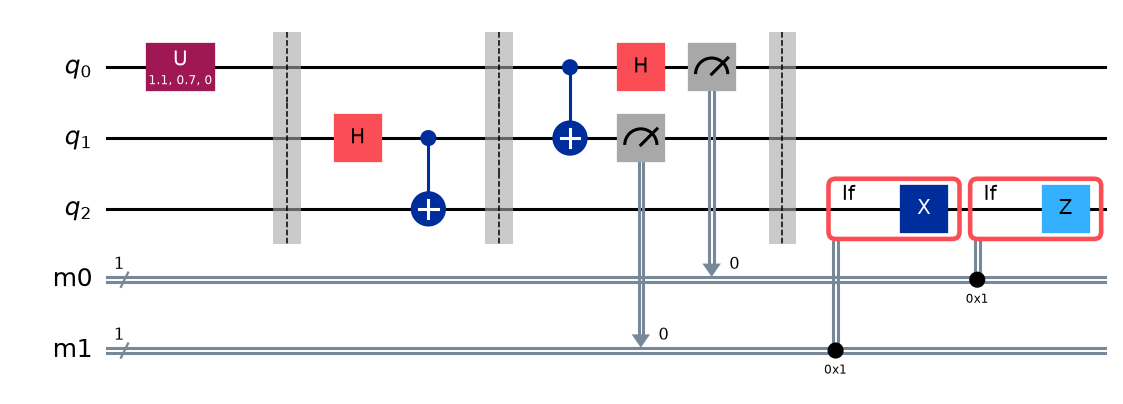

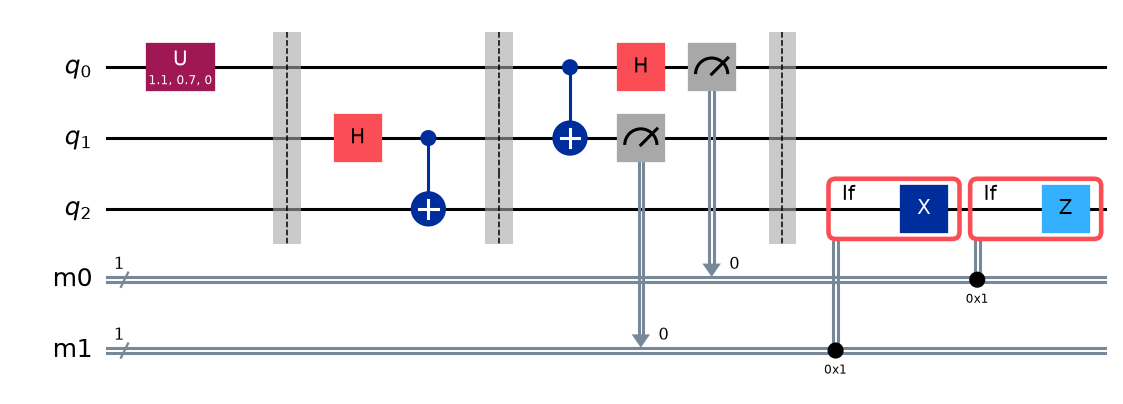

In [2]:
theta, phi = 1.1, 0.7
qc = teleport.teleport_circuit(theta, phi, 'dynamic')
qc.draw('mpl', fold=-1)

### Variant B: deferred measurement (quantum-controlled corrections; runs on any backend)

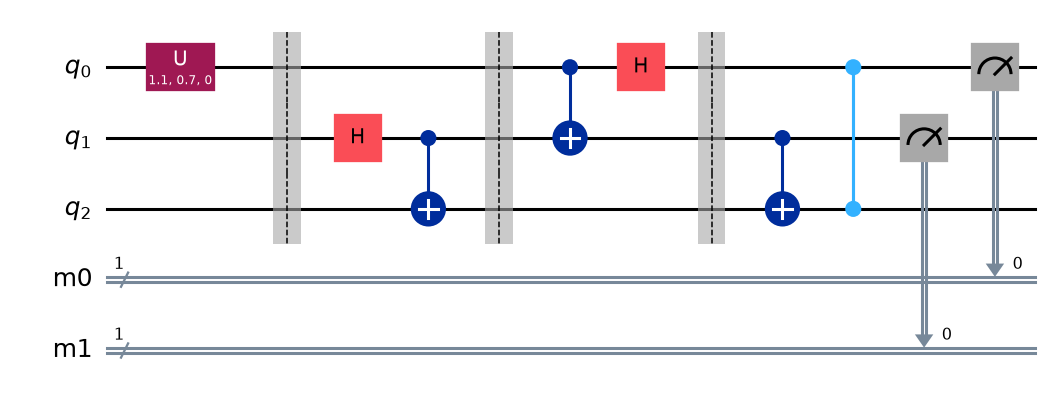

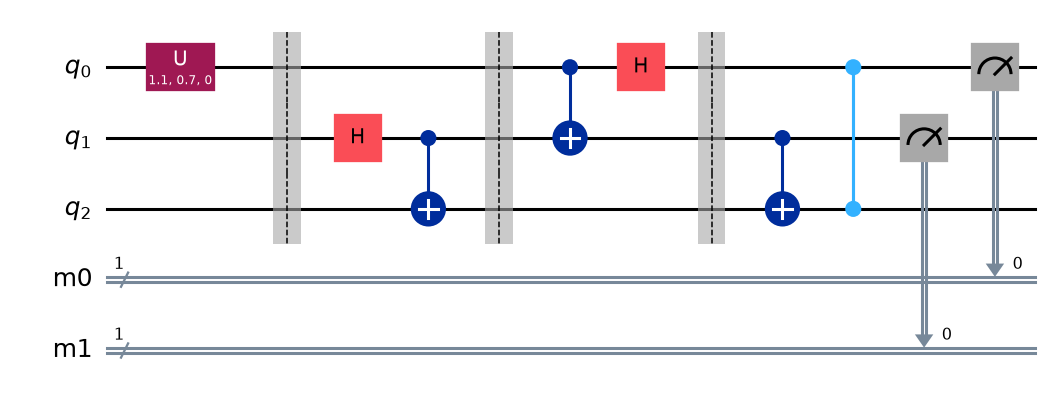

In [3]:
teleport.teleport_circuit(theta, phi, 'deferred').draw('mpl', fold=-1)

## 2. Watching it happen: Bloch vectors after every gate (Variant C, step engine)
We evolve the 3-qubit **density matrix** gate by gate and take the reduced state of each qubit (partial trace). A Bloch vector **shorter than 1** means that qubit is *mixed*. Halves of an entangled pair look maximally mixed ($|r|=0$) on their own.

init       |r| = [1.0, 1.0, 1.0]  F(Bob)=0.7268  All three qubits start in |0>.
prepare    |r| = [1.0, 1.0, 1.0]  F(Bob)=0.7268  Alice prepares the secret state |psi> on q0.
bell_h     |r| = [1.0, 1.0, 1.0]  F(Bob)=0.7268  Hadamard on q1 puts it in superposition.
bell_cx    |r| = [1.0, 0.0, 0.0]  F(Bob)=0.5000  CNOT entangles q1 and q2 into a Bell pair; both arrows shrink to the c
bsm_cx     |r| = [0.454, 0.0, 0.0]  F(Bob)=0.5000  Alice applies CNOT(q0 -> q1): |psi> becomes entangled with the pair.
bsm_h      |r| = [0.454, 0.0, 0.0]  F(Bob)=0.5000  Hadamard on q0 completes the rotation into the Bell basis.
measure    |r| = [1.0, 1.0, 1.0]  F(Bob)=0.4646  Alice measures: m0=0, m1=1. q0's original state is destroyed (no-cloni
classical  |r| = [1.0, 1.0, 1.0]  F(Bob)=0.4646  Alice sends two classical bits (01) to Bob. Nothing travels faster tha
correct_x  |r| = [1.0, 1.0, 1.0]  F(Bob)=1.0000  m1=1 -> Bob applies X.
correct_z  |r| = [1.0, 1.0, 1.0]  F(Bob)=1.0000  m0=0 -> no Z needed.
done

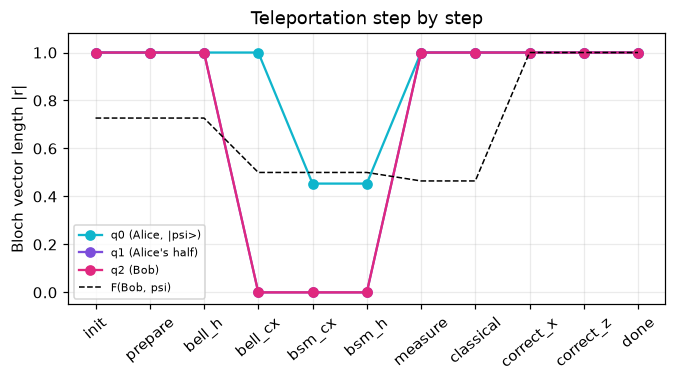

In [4]:
steps = teleport.TeleportStepper(theta, phi, rand=np.random.default_rng(7).random).run()
for s in steps:
    print(f"{s.name:10s} |r| = {[round(float(np.linalg.norm(v)),3) for v in s.bloch]}  F(Bob)={s.fidelity_bob:.4f}  {s.caption[:70]}")
plots.bloch_lengths(steps); plt.show()

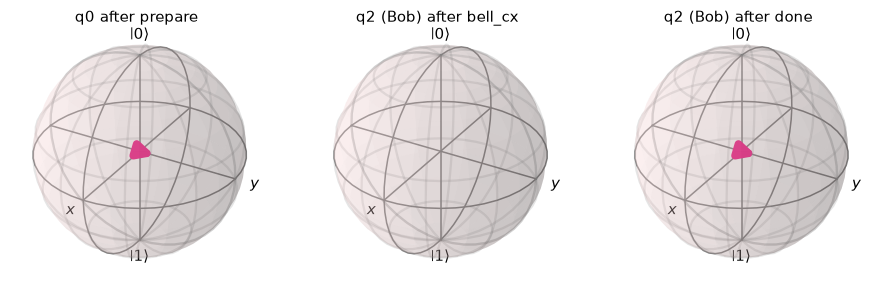

In [5]:
from qiskit.visualization import plot_bloch_vector
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), subplot_kw={'projection': '3d'})
for ax, name in zip(axes, ['prepare', 'bell_cx', 'done']):
    s = next(x for x in steps if x.name == name)
    plot_bloch_vector(s.bloch[0] if name == 'prepare' else s.bloch[2], ax=ax, title=f"{'q0' if name=='prepare' else 'q2 (Bob)'} after {name}")
plt.show()

## 3. Verification
### 3a. Exact fidelity in every measurement branch
Using Aer's `save_density_matrix(conditional=True)` we get Bob's exact density matrix **separately for each of the four outcomes** $(m_0,m_1)$ and compute $F=\langle\psi|\rho_B|\psi\rangle$.

In [6]:
res = teleport.exact_fidelity(theta, phi, shots=4000)
for k, v in res['branches'].items(): print(f"{k}:  P = {v['probability']:.3f}   F = {v['fidelity']:.12f}")
print('branch-averaged F =', res['fidelity'])

m0=0,m1=1:  P = 0.255   F = 1.000000000000
m0=1,m1=0:  P = 0.250   F = 1.000000000000
m0=1,m1=1:  P = 0.251   F = 1.000000000000
m0=0,m1=0:  P = 0.244   F = 1.000000000000
branch-averaged F = 0.9999999999999994


### 3b. Measurement-based state tomography (our own implementation)
Measure Bob in the Z, X ($H$ before measuring) and Y ($S^\dagger H$) bases; $\langle\sigma\rangle = P(0)-P(1)$ reconstructs $\vec r_{out}$, and for a pure input $F = (1+\vec r_{in}\cdot\vec r_{out})/2$. Finite-shot estimates with $|r|>1$ are projected onto the Bloch ball.

In [7]:
t = teleport.run_tomography(theta, phi, shots=8192)
print('r_in  =', np.round(t['r_in'], 4)); print('r_out =', np.round(t['r_out'], 4)); print('tomography F =', round(t['fidelity'], 5))

r_in  = [0.6816 0.5741 0.4536]
r_out = [0.6823 0.571  0.4566]
tomography F = 1.0


### 3c. 200 Haar-random states, with angles drawn from the QRNG entropy pool: $\cos\theta\sim U[-1,1]$, $\varphi\sim U[0,2\pi)$

ideal exact : mean=1.000000000000  min=1.000000000000
noisy exact : mean=0.8600 +- 0.0081  min=0.8422


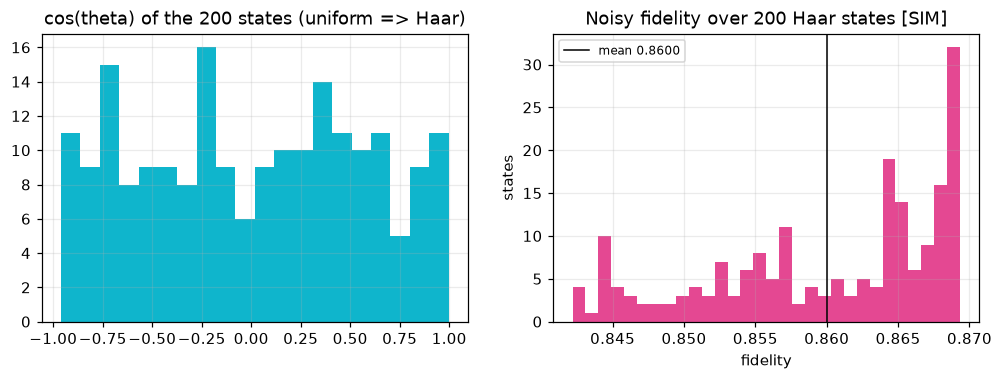

In [8]:
pool = EntropyPool(load_pool('../data/qrng_pool_sim.bin'), source='SIM')
angles = [pool.haar_angles() for _ in range(200)]
ideal = teleport.haar_average(angles=angles)
noisy = teleport.haar_average(angles=angles, noise=NoiseSpec(p1=0.01, p2=0.1, readout=0.02))
print(f"ideal exact : mean={ideal['mean']:.12f}  min={ideal['min']:.12f}")
print(f"noisy exact : mean={noisy['mean']:.4f} +- {noisy['std']:.4f}  min={noisy['min']:.4f}")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
th = [a[0] for a in angles]; ax[0].hist(np.cos(th), bins=20, color=plots.CYAN); ax[0].set_title('cos(theta) of the 200 states (uniform => Haar)')
plots.fidelity_hist(noisy['fidelities'], 'Noisy fidelity over 200 Haar states [SIM]', ax=ax[1]); plt.show()

### 3d. Exhaustive cardinal-state test and the process (Pauli transfer matrix)
The six states $|0\rangle,|1\rangle,|\pm\rangle,|\pm i\rangle$ fully determine the single-qubit channel. From their outputs we build the PTM $R_{ij}=\tfrac12\mathrm{Tr}[\sigma_i\,\mathcal E(\sigma_j)]$. The ideal channel gives $R=I$. Average fidelity follows exactly as $F_{avg}=(2F_{pro}+1)/3$ with $F_{pro}=\mathrm{Tr}R/4$.

{'|0>': 1.0, '|1>': 1.0, '|+>': 1.0, '|->': 1.0, '|+i>': 1.0, '|-i>': 1.0}


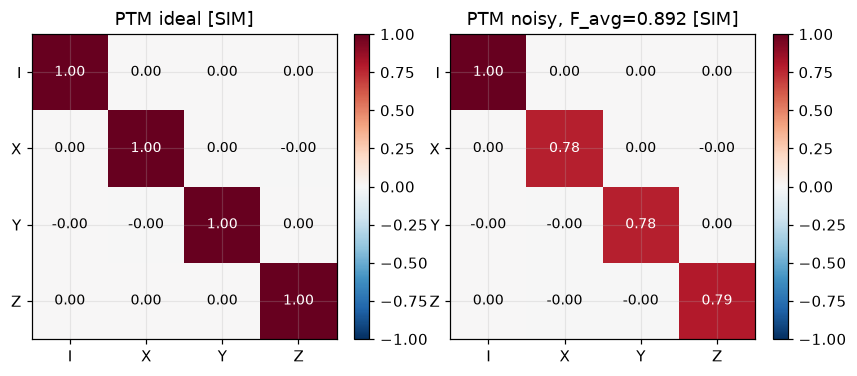

In [9]:
ci = teleport.cardinal_state_test(); cn = teleport.cardinal_state_test(NoiseSpec(p1=0.01, p2=0.1))
print({k: round(v, 9) for k, v in ci['fidelities'].items()})
fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
plots.ptm(ci['ptm'], 'PTM ideal [SIM]', ax=ax[0]); plots.ptm(cn['ptm'], f"PTM noisy, F_avg={cn['average_fidelity']:.3f} [SIM]", ax=ax[1]); plt.show()

## 4. Why 2/3 is the line that matters
A *classical* channel (Alice measures $|\psi\rangle$, phones the result, Bob re-prepares) achieves at best average fidelity **2/3** (Massar & Popescu 1995). Only $F_{avg} > 2/3$ certifies that the entanglement did real work.

## 5. Noise analysis
Noise is inserted as explicit error channels after every gate (`qrelay.noise.noisify`). We sweep 2-qubit depolarizing $p_2$ (with $p_1=p_2/10$). For CX-only noise the closed form $F=(1+(1-p_2)^2)/2$ is derived in THEORY.md, and the simulation matches it exactly.

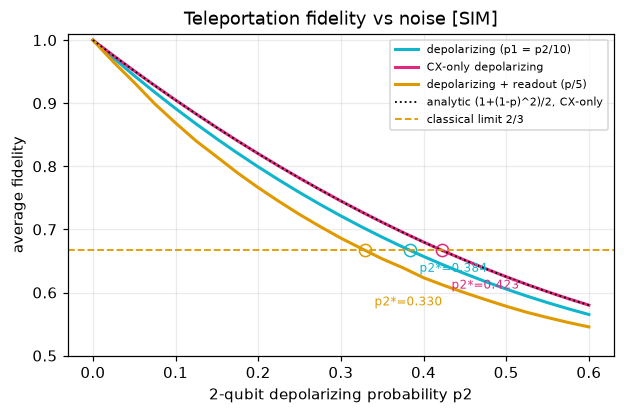

quantum-advantage thresholds (F crosses 2/3): {'depolarizing (p1 = p2/10)': 0.384, 'CX-only depolarizing': 0.4227, 'depolarizing + readout (p/5)': 0.3296}


In [10]:
sw = sweep('teleport_sweep_1d'); plots.teleport_sweep(sw); plt.show()
print('quantum-advantage thresholds (F crosses 2/3):', {k: (round(v,4) if v else None) for k, v in sw['crossings'].items()})

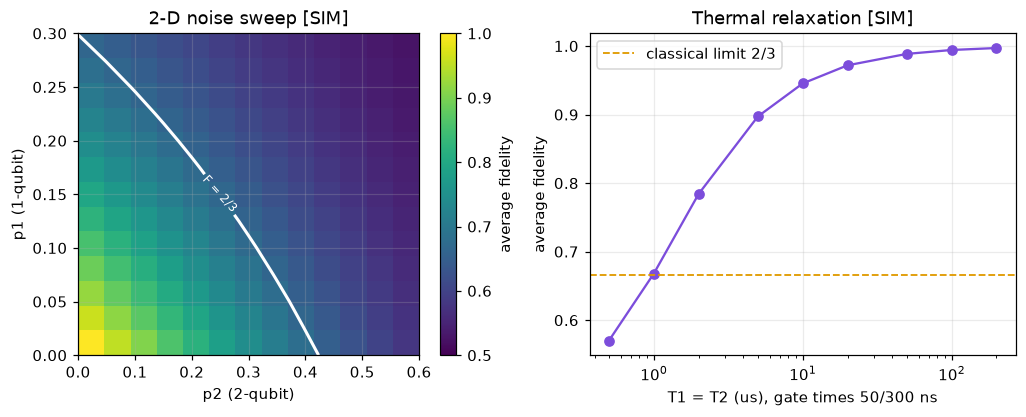

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
plots.teleport_heatmap(sweep('teleport_sweep_2d'), ax=ax[0])
t1 = sweep('teleport_t1_sweep'); ax[1].semilogx(t1['t1_us'], t1['fidelity'], 'o-', color=plots.VIOLET); plots.classical_line(ax[1])
ax[1].set(xlabel='T1 = T2 (us), gate times 50/300 ns', ylabel='average fidelity', title='Thermal relaxation [SIM]'); ax[1].legend(); plt.show()

### Readout-error mitigation
Inverting the measured confusion matrix fixes errors in **Bob's** final readout. It cannot fix readout errors on **Alice's mid-circuit** bits, which make Bob apply the wrong correction. So for $|+\rangle$ with readout flip $p$ the mitigated ceiling is $1-p$. Mitigation helps, but there is a physical ceiling.

In [12]:
spec = NoiseSpec(readout=0.08)
r = teleport.run_tomography(math.pi/2, 0, spec, shots=20000, mitigate=True)
print(f"raw F = {r['fidelity']:.4f}   mitigated F = {r['fidelity_mitigated']:.4f}   (ceiling 1 - p = {1-0.08:.2f})")

raw F = 0.8535   mitigated F = 0.9240   (ceiling 1 - p = 0.92)


## 6. Real-device / emulated results
Loaded from `data/hardware/` (written by `scripts/run_hardware.py`). Every number below carries its source label.

[HW] backend=ibm_marrakesh  job_id=dbgnmpote5oc738iia1g  time=2026-10-28T10:13:49
   deferred  F_avg=0.9782  per state: {'|0>': 0.984, '|1>': 0.969, '|+>': 0.964, '|->': 0.967, '|+i>': 0.965, '|-i>': 0.958}
   dynamic   F_avg=0.8798  per state: {'|0>': 0.976, '|1>': 0.962, '|+>': 0.831, '|->': 0.819, '|+i>': 0.826, '|-i>': 0.816}


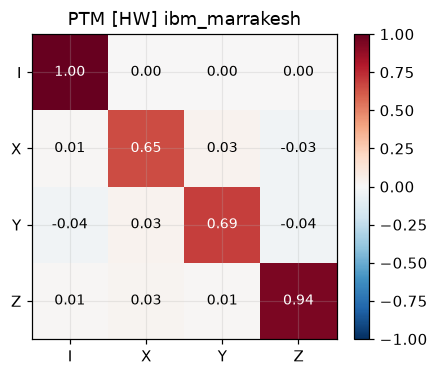

[EMU] backend=fake_brisbane  job_id=None  time=2026-10-27T22:36:55
   deferred  F_avg=0.9650  per state: {'|0>': 0.977, '|1>': 0.977, '|+>': 0.969, '|->': 0.963, '|+i>': 0.955, '|-i>': 0.958}
   dynamic   F_avg=0.9615  per state: {'|0>': 0.966, '|1>': 0.969, '|+>': 0.967, '|->': 0.962, '|+i>': 0.951, '|-i>': 0.954}


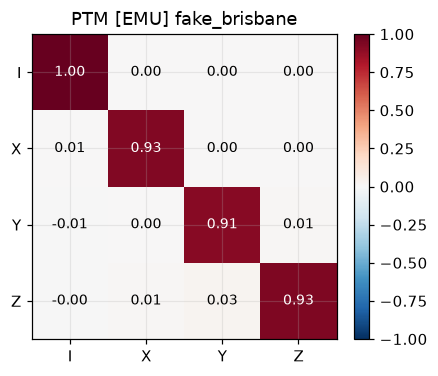

In [13]:
for src in ('HW', 'EMU'):
    rec = hardware.latest(src)
    if rec is None:
        print(f'[{src}] not available'); continue
    a = hardware.analyze(rec)
    print(f"[{src}] backend={a['backend']}  job_id={a['job_id']}  time={a['timestamp']}")
    for v, tv in a['teleport'].items():
        print(f"   {v:9s} F_avg={tv['average_fidelity']:.4f}  per state:", {k: round(x['fidelity'], 3) for k, x in tv['states'].items()})
    best = a['teleport'].get('dynamic') or a['teleport']['deferred']
    plots.ptm(best['ptm'], f"PTM [{src}] {a['backend']}"); plt.show()

## Conclusions
* The dynamic-circuit protocol teleports arbitrary states with fidelity 1 (to 1e-12) in **every** branch. Tomography and a 200-state Haar average agree.
* With noise, fidelity falls smoothly. The **2/3 crossing** marks where the channel stops beating any classical strategy ($p_2^*\approx0.38$ for our model).
* On the emulated device, average fidelity is well above 2/3 (see section 6), and readout mitigation gives a measurable gain up to a physical ceiling.